In [49]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import numpy as np
import xarray as xr

from unseen import fileio

In [50]:
map_proj = ccrs.PlateCarree(central_longitude=180)

box_name = 'Central Pakistan'
box_lat0 = 24
box_lat1 = 33
box_lon0 = 65
box_lon1 = 71

In [53]:
infiles = {
    'MSWEP': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_MSWEP_1979-2025_annual_asia.nc',
    'CPC': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_CPC_1979-2025_annual_asia.nc',
    'ERA5': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_ERA5_1940-2025_annual_asia.nc',
#    'BCC-CSM2-MR': '',
    'CMCC-CM2-SR5': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_CMCC-CM2-SR5-dcppA-hindcast_196011-201911_annual_asia.nc',
    'CanESM5': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_CanESM5-dcppA-hindcast_196101-201701_annual_asia.nc',
#    'EC-Earth3': '',
    'IPSL-CM6A-LR': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_IPSL-CM6A-LR-dcppA-hindcast_196101-201701_annual_asia.nc',
    'MIROC6': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_MIROC6-dcppA-hindcast_196011-201811_annual_asia.nc',
    'MPI-ESM1-2-HR': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_MPI-ESM1-2-HR-dcppA-hindcast_196011-201811_annual_asia.nc',
    'MRI-ESM2-0': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_MRI-ESM2-0-dcppA-hindcast_196011-201911_annual_asia.nc',
    'NorCPM1': '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/pr-jul-aug_NorCPM1-dcppA-hindcast_196010-201810_annual_asia.nc',
}

In [54]:
clim_dict = {}
for dataset, infile in infiles.items():
    ds = xr.open_dataset(infile)
    if dataset in ['MSWEP', 'ERA5', 'CPC']:
        clim_dict[dataset] = ds['pr'].mean('time').compute()
    else:
        clim_dict[dataset] = ds['pr'].mean(['init_date', 'ensemble', 'lead_time']).compute()

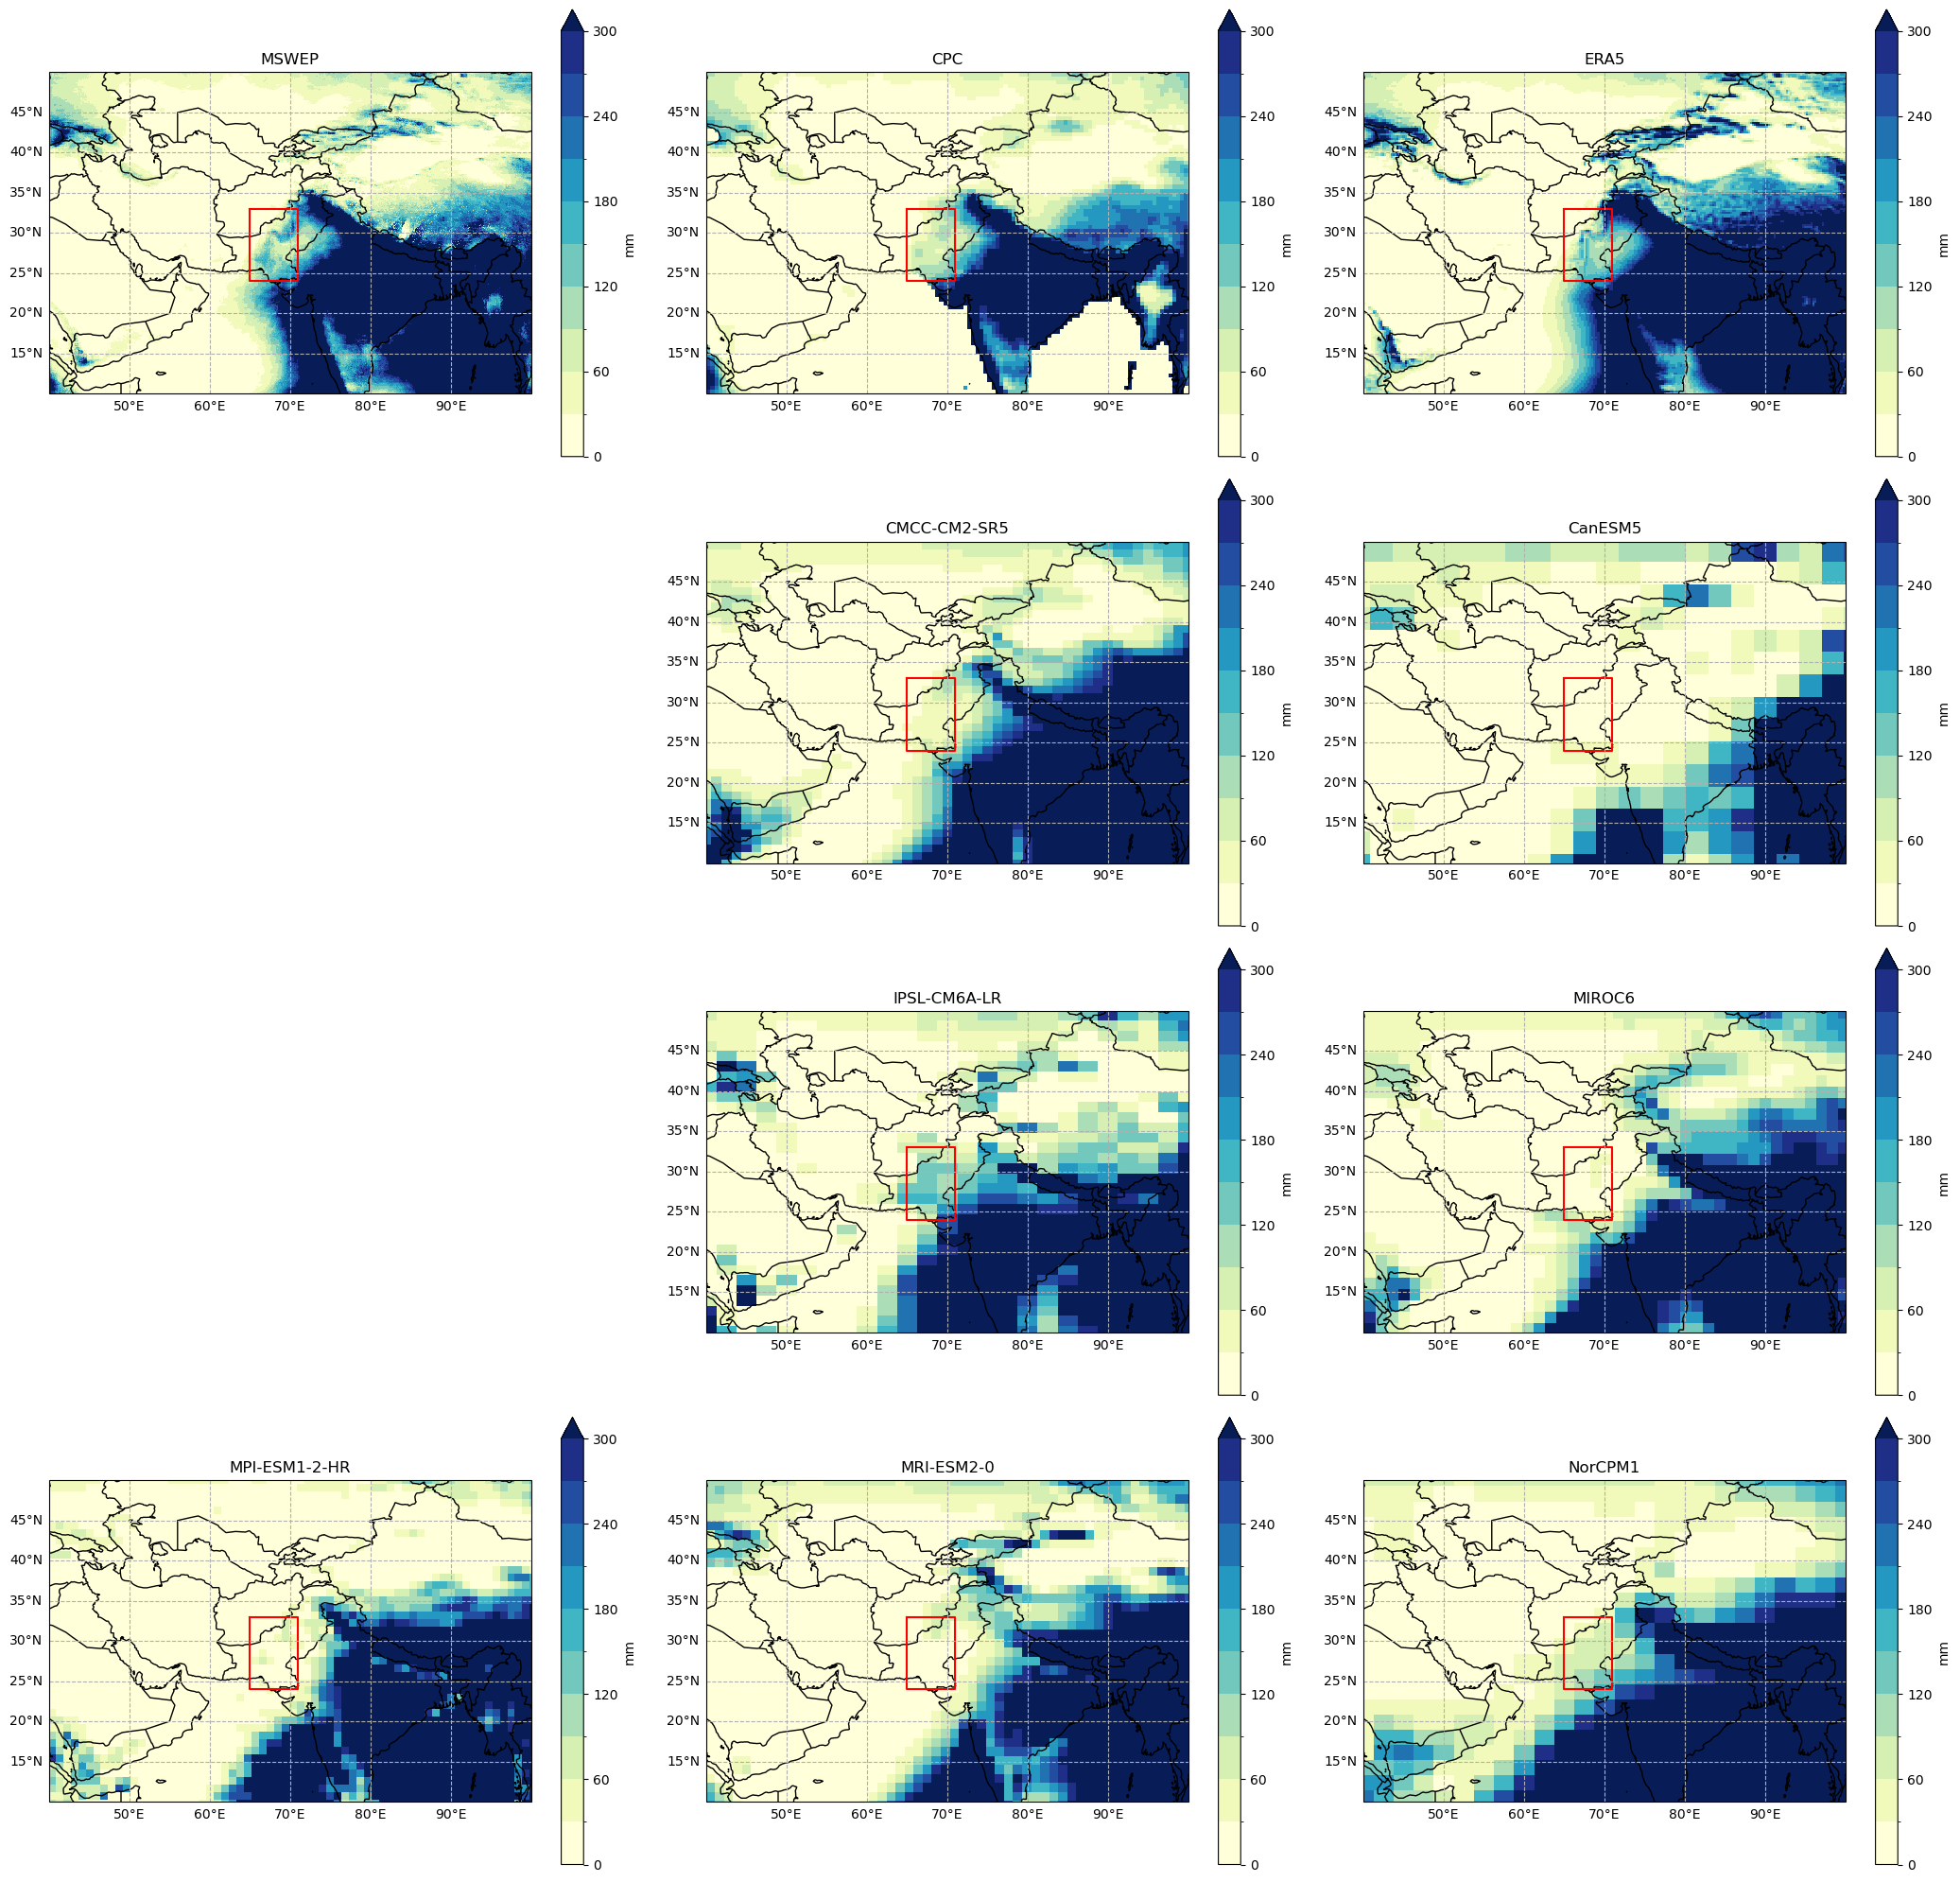

In [55]:
nrows = 4
ncols = 3

fig = plt.figure(figsize=[7*ncols, 5*nrows])
ax_dict = {}
ax_dict['MSWEP'] = fig.add_subplot(nrows, ncols, 1, projection=map_proj)
ax_dict['CPC'] = fig.add_subplot(nrows, ncols, 2, projection=map_proj)
ax_dict['ERA5'] = fig.add_subplot(nrows, ncols, 3, projection=map_proj)
#ax_dict['BCC-CSM2-MR'] = fig.add_subplot(nrows, ncols, 4, projection=map_proj)
ax_dict['CMCC-CM2-SR5'] = fig.add_subplot(nrows, ncols, 5, projection=map_proj)
ax_dict['CanESM5'] = fig.add_subplot(nrows, ncols, 6, projection=map_proj)
#ax_dict['EC-Earth3'] = fig.add_subplot(nrows, ncols, 7, projection=map_proj)
ax_dict['IPSL-CM6A-LR'] = fig.add_subplot(nrows, ncols, 8, projection=map_proj)
ax_dict['MIROC6'] = fig.add_subplot(nrows, ncols, 9, projection=map_proj)
ax_dict['MPI-ESM1-2-HR'] = fig.add_subplot(nrows, ncols, 10, projection=map_proj)
ax_dict['MRI-ESM2-0'] = fig.add_subplot(nrows, ncols, 11, projection=map_proj)
ax_dict['NorCPM1'] = fig.add_subplot(nrows, ncols, 12, projection=map_proj)

levels = np.arange(0, 301, 30)

for dataset, ax in ax_dict.items():
    clim_dict[dataset].plot(
        ax=ax_dict[dataset],
        transform=ccrs.PlateCarree(),
        cmap='YlGnBu',
        levels=levels,
        extend='max',
        cbar_kwargs={"label": 'mm'},
    )
    ax.plot(
        [box_lon0, box_lon0, box_lon1, box_lon1, box_lon0],
        [box_lat1, box_lat0, box_lat0, box_lat1, box_lat1],
        transform=ccrs.PlateCarree(),
        color='red',
    )   
    ax.coastlines()
    ax.set_extent([40, 100, 10, 50], crs=ccrs.PlateCarree(central_longitude=0))
    ax.add_feature(cartopy.feature.BORDERS)
    gl = ax.gridlines(linestyle="--", draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    ax.set_title(dataset)

#plt.suptitle('Climatological mean Jul-Aug annual accumulated rainfall', ha='center')
plt.tight_layout()
plt.show()